In [5]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
import eda

In [22]:
n_obj = 2
n_items = 20
n_selected = 5
rho = 0.3
data = np.load(f'problems/items_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz')
items = data['items']
capacity = data['capacity']

In [7]:
eda_run = eda.KnapsackEDA(
    items=items,
    capacity=capacity,
    n_selected=n_selected,
    n_obj=n_obj,
    pop_size=1000,
    generations=100,
    max_no_improve_gen=3,
    max_row_diff=0.1,
    seed=1123,
)
results = eda_run.run()
pf_eda = results["converged_pf_table"][-1]
ps_eda = results["converged_pf_population_table"][-1]
np.savez(f"results/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz", pf_eda)

Mode 1 generation 1 (no improve count: 0)
Mode 1 generation 2 (no improve count: 0)
Mode 1 generation 3 (no improve count: 0)
Mode 1 generation 4 (no improve count: 0)
Mode 1 generation 5 (no improve count: 0)
Mode 1 generation 6 (no improve count: 0)
Mode 1 generation 7 (no improve count: 0)
Mode 1 generation 8 (no improve count: 0)
Mode 1 generation 9 (no improve count: 1)
Mode 1 generation 10 (no improve count: 0)
Mode 1 generation 11 (no improve count: 1)
Mode 1 generation 12 (no improve count: 2)
Mode 2 generation 1 (no improve count: 0)
Mode 2 generation 2 (no improve count: 0)
Mode 2 generation 3 (no improve count: 1)
Mode 2 generation 4 (no improve count: 2)
EDA finished in 5.67s (mode 1: 12 gens, mode 2: 4 gens)


In [23]:
pf_exact = np.load(f"results/exact_front_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_ks = np.load(f"results/KS_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["pf"]
pf_eda = np.load(f"results/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["arr_0"]

In [24]:
print(pf_exact.shape)
print(pf_ks.shape)
print(pf_eda.shape)


(18, 2)
(18, 2)
(18, 2)


In [26]:
np.allclose(
    np.unique(np.round(pf_eda), axis=0),
    np.unique(np.round(pf_exact), axis=0),
)

True

In [ ]:
pf_eda_pd = pd.read_csv("../card_game/eda_results/pf_trial0.csv", header=None)
pf_eda = np.array(pf_eda_pd)
pf_eda = np.load("problems/pf_1_eda.npz")["arr_0"]
pf_KirlikSayin_no_constraint = np.load("problems/pf_1_no_constraint.npz")["pf"]
pf_KirlikSayin = np.load("problems/pf_1.npz")["pf"]
pf_TV = np.load("problems/pf_1_TV.npz")["pf"]

In [4]:
pf_eda.shape

(27, 2)

In [5]:
pf_KirlikSayin.shape

(20, 2)

In [15]:
pf_TV.shape

(22, 2)

In [9]:
np.allclose(pf_KirlikSayin, pf_KirlikSayin_no_constraint)

True

In [11]:
def rows_not_in(a, b, atol=1e-8, rtol=1e-5):
    """Rows of `a` that do not appear (approx.) in `b`."""
    mask = np.ones(len(a), dtype=bool)
    for i, row in enumerate(a):
        if np.any(np.all(np.isclose(b, row, atol=atol, rtol=rtol), axis=1)):
            mask[i] = False
    return a[mask], np.where(mask)[0]
missing, idx = rows_not_in(pf_eda[:, :n_obj], pf_KirlikSayin)
print(idx)      # indices into pf_eda
print(missing)

[ 4  6  8  9 14 20 24]
[[ 31.42 123.51]
 [ 54.55 111.68]
 [ 57.71 101.88]
 [ 59.35 101.62]
 [ 73.1   87.45]
 [ 83.73  59.24]
 [ 93.12  34.33]]


In [17]:
missing, idx = rows_not_in(pf_TV, pf_KirlikSayin)
print(idx)     
print(missing)

[14 17]
[[ 59.35 101.62]
 [ 31.42 123.51]]


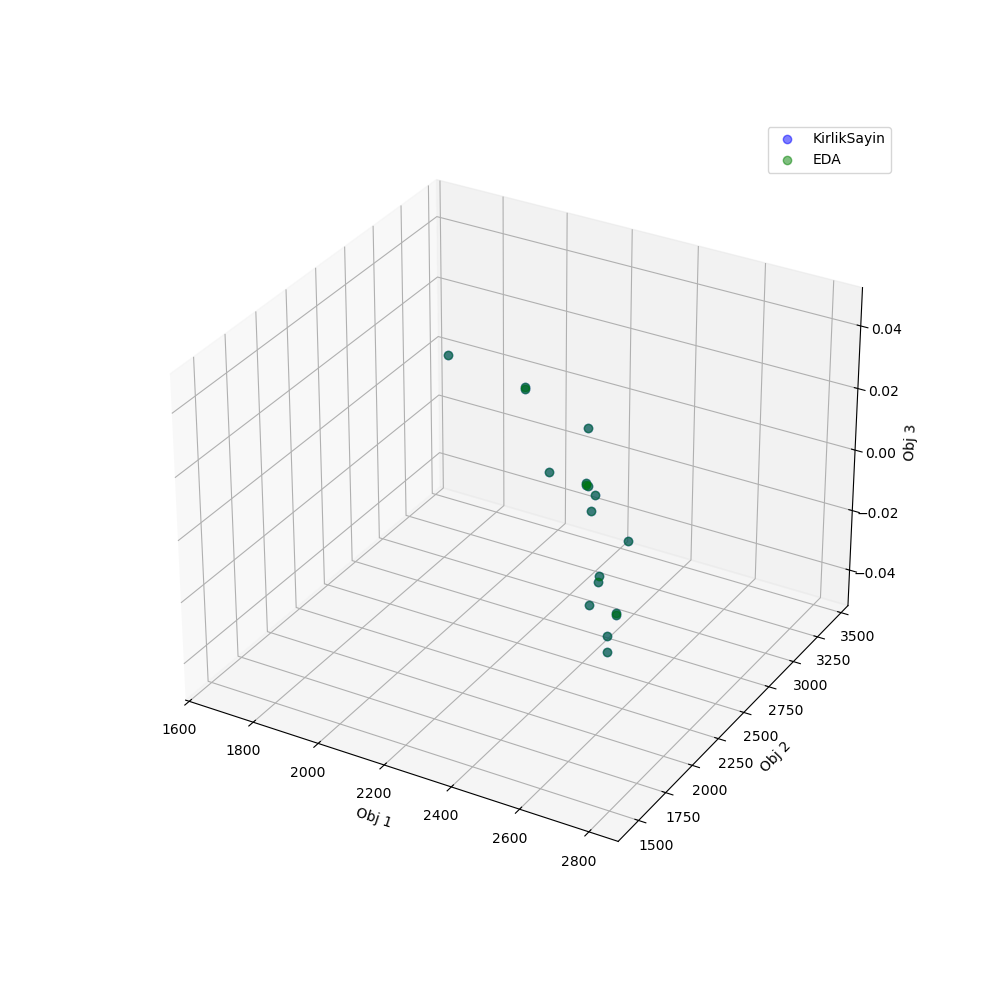

In [ ]:
import matplotlib.pyplot as plt
%matplotlib widget
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')
ax.plot(pf_eda[:,0], pf_eda[:,1], pf_eda[:,2], 'bo', alpha=0.5, markersize=6, label="KirlikSayin")
ax.plot(pf_exact[:,0], pf_exact[:,1], pf_exact[:,2], 'go', alpha=0.5, markersize=6, label="EDA")
ax.set_xlabel('Obj 1')
ax.set_ylabel('Obj 2')
ax.set_zlabel('Obj 3')
ax.legend()
plt.show()

In [29]:
from pymoo.indicators.hv import HV

ref_point = np.zeros(n_obj)
hv = HV(ref_point=ref_point)
hv_pf_eda = hv(-pf_eda)
hv_pf_ks = hv(-pf_ks)
print(hv_pf_ks)
print(hv_pf_eda)

8791080.0
8791080.0


In [14]:
def calculate_dominated(pf_predicted, pf_actual, n_obj):
    dominated = np.zeros(len(pf_predicted))
    for i in range(len(pf_predicted)):
        for j in range(len(pf_actual)):
            if np.all(pf_actual[j, :n_obj] >= pf_predicted[i, :n_obj]) and \
                np.any(pf_actual[j, :n_obj] > pf_predicted[i, :n_obj]):
                dominated[i] = 1
                break
    return np.sum(dominated), np.sum(dominated)/len(pf_predicted)

num_dominated, ratio_dominated = calculate_dominated(pf_eda, pf_ks, 3)
print("% of eda dominated by ks: ", ratio_dominated)
num_dominated, ratio_dominated = calculate_dominated(pf_ks, pf_eda, 3)
print("% of ks dominated by eda: ", ratio_dominated)

% of eda dominated by ks:  0.038461538461538464
% of ks dominated by eda:  0.017985611510791366
